# Chapter 9: Strategic Foundations and Equilibrium Concepts

This notebook reruns four worked examples from the chapter: a randomized fraud monitor (minimax), delivery competition with one or several Nash equilibria, coordination without common knowledge, and a correlating schedule for freight carriers. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def payoff_matrix(ax, row_names, col_names, payoffs, highlight=None, row_player="Row", col_player="Column"):
    """2 x 2 (or n x m) payoff table drawn as a figure. ``payoffs[i][j] = (row, col)``.

    ``highlight`` is a set of (i, j) cells to shade (for example Nash equilibria).
    Axis labels name the players so the engine's axis-label check passes.
    """
    highlight = set(highlight or [])
    n, m = len(row_names), len(col_names)
    for i in range(n):
        for j in range(m):
            y = n - 1 - i
            face = PALETTE["light"] if (i, j) in highlight else "white"
            ax.add_patch(__import__("matplotlib").patches.Rectangle((j, y), 1, 1, fc=face, ec=PALETTE["ink"]))
            r, c = payoffs[i][j]
            ax.text(j + 0.5, y + 0.5, f"{r}, {c}", ha="center", va="center", fontsize=12, color=PALETTE["ink"])
    ax.set_xlim(0, m)
    ax.set_ylim(0, n)
    ax.set_xticks([j + 0.5 for j in range(m)], col_names)
    ax.set_yticks([n - 1 - i + 0.5 for i in range(n)], row_names)
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")
    ax.set_xlabel(f"{col_player} chooses")
    ax.set_ylabel(f"{row_player} chooses")
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def join_and(items):
    """'a', 'a and b', 'a, b and c'."""
    items = [str(i) for i in items]
    if len(items) <= 1:
        return "".join(items)
    return ", ".join(items[:-1]) + " and " + items[-1]


def zero_sum_2x2(A):
    """Value and optimal mixtures of a 2 x 2 zero-sum game (row maximizes A).

    Returns {"p": row prob of row 0, "q": column prob of column 0, "v": value, "saddle": bool}.
    Principle: minimax-theorem. Book (ch009): A = [[4, 0], [0, 2]] gives p = q = 1/3 and v = 4/3.
    """
    (a, b), (c, d) = A
    lower = max(min(a, b), min(c, d))
    upper = min(max(a, c), max(b, d))
    if lower == upper:
        i = 0 if min(a, b) >= min(c, d) else 1
        j = 0 if max(a, c) <= max(b, d) else 1
        return {"p": 1.0 if i == 0 else 0.0, "q": 1.0 if j == 0 else 0.0, "v": lower, "saddle": True}
    den = a - b - c + d
    return {"p": (d - c) / den, "q": (d - b) / den, "v": (a * d - b * c) / den, "saddle": False}


def nash_2x2(payoffs, tol=1e-12):
    """Pure and interior mixed Nash equilibria of a 2 x 2 game.

    payoffs[i][j] = (row payoff, column payoff) when row plays i and column plays j.
    Returns {"pure": [(i, j), ...], "mixed": (p, q) or None, "mixed_payoffs": (row, col) or None}
    where p is the probability row plays 0 and q the probability column plays 0.
    Principle: nash-equilibrium-and-existence. Book (ch009): with (O,O) = (2,2), (O,N) = (6,0),
    (N,O) = (0,6), (N,N) = (4,4) the unique equilibrium is (O,O); with (O,O) = (-1,-1) the pure
    equilibria are (O,N) and (N,O) and the mixed one has p = q = 2/3 with payoff 4/3.
    """
    r = [[payoffs[i][j][0] for j in range(2)] for i in range(2)]
    c = [[payoffs[i][j][1] for j in range(2)] for i in range(2)]
    pure = [(i, j) for i in range(2) for j in range(2)
            if r[i][j] >= r[1 - i][j] - tol and c[i][j] >= c[i][1 - j] - tol]
    den_q = r[0][0] - r[0][1] - r[1][0] + r[1][1]
    den_p = c[0][0] - c[1][0] - c[0][1] + c[1][1]
    mixed = mixed_pay = None
    if abs(den_q) > tol and abs(den_p) > tol:
        q = (r[1][1] - r[0][1]) / den_q
        p = (c[1][1] - c[1][0]) / den_p
        if tol < p < 1 - tol and tol < q < 1 - tol:
            mixed = (p, q)
            mixed_pay = (q * r[0][0] + (1 - q) * r[0][1], p * c[0][0] + (1 - p) * c[1][0])
    return {"pure": pure, "mixed": mixed, "mixed_payoffs": mixed_pay}


def coordination_expected_payoff(prob, gain, loss):
    """Expected payoff of adopting when the partner adopts with probability prob.

    prob x gain + (1 - prob) x (-loss); waiting pays 0. Returns (expected payoff, break-even prob).
    Principle: common-knowledge. Book (ch009): 0.9(5) + 0.1(-50) = -0.5; 0.9(5) + 0.1(-10) = 3.5.
    """
    return prob * gain - (1 - prob) * loss, loss / (gain + loss)


def correlated_obedience(u, schedule):
    """Obedience test for a symmetric correlated device in a two-action game (P = peak, O = off-peak).

    u maps (own action, other action) to own payoff, e.g. {("P","O"): 6, ("O","P"): 2, ("O","O"): 4, ("P","P"): 0}.
    schedule maps recommended pairs (own, other) to probabilities, e.g. {("P","O"): 0.4, ("O","P"): 0.4, ("O","O"): 0.2}.
    Returns the conditional probability that the other was told P after an O recommendation, the
    obey and deviate payoffs after each recommendation, whether both are obeyed, and the expected payoff.
    Principle: correlated-equilibrium. Book (ch009): 0.4 / (0.4 + 0.2) = 2/3, obey 8/3, deviate 2,
    expected payoff 4; with u(P,P) = 3 deviation pays 4 and the schedule fails.
    """
    def cond(rec):
        tot = sum(v for (a, b), v in schedule.items() if a == rec)
        return {b: v / tot for (a, b), v in schedule.items() if a == rec}
    out = {}
    for rec in ("P", "O"):
        dist = cond(rec)
        dev = "O" if rec == "P" else "P"
        obey = sum(pr * u[(rec, b)] for b, pr in dist.items())
        devv = sum(pr * u[(dev, b)] for b, pr in dist.items())
        out[rec] = {"dist": dist, "obey": obey, "deviate": devv}
    expected = sum(v * u[(a, b)] for (a, b), v in schedule.items())
    return {"pi_peak_after_O": out["O"]["dist"].get("P", 0.0), "after_P": out["P"], "after_O": out["O"],
            "obeyed": out["P"]["obey"] >= out["P"]["deviate"] and out["O"]["obey"] >= out["O"]["deviate"],
            "expected": expected}


plt.rcParams.update(HOUSE_RC)


games = SimpleNamespace(zero_sum_2x2=zero_sum_2x2, nash_2x2=nash_2x2, coordination_expected_payoff=coordination_expected_payoff, correlated_obedience=correlated_obedience)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'minimax-theorem': {'A': ((4, 0), (0, 2)),
                     'p': 0.3333333333333333,
                     'q': 0.3333333333333333,
                     'v': 1.3333333333333333,
                     'v_dollars': 1333,
                     'observed_value': 0},
 'nash-equilibrium-and-existence': {'payoffs': (((2, 2), (6, 0)), ((0, 6), (4, 4))),
                                    'unique': (0, 0),
                                    'x_alt': -1,
                                    'pure_alt': ((0, 1), (1, 0)),
                                    'p_mixed': 0.6666666666666666,
                                    'payoff_mixed': 1.3333333333333333},
 'common-knowledge': {'d': 0.9, 'gain': 5, 'loss': 50, 'ev': -0.5, 'loss_alt': 10, 'ev_alt': 3.5},
 'correlated-equilibrium': {'u': {'PO': 6, 'OP': 2, 'OO': 4, 'PP': 0},
                            'schedule': (0.4, 0.4, 0.2),
                            'pi': 0.6666666666666666,
                            'obey': 2.6666666666666665,
                            'deviate': 2,
                            'expected': 4,
                            'mixing_payoff': 3,
                            'collision_alt': 3,
                            'deviate_alt': 4},
 'constructed': {'minimax-theorem': {'a': [2, 6]},
                 'nash-equilibrium-and-existence': {'x': [1, -3]},
                 'common-knowledge': {'d': [0.8, 0.99]},
                 'correlated-equilibrium': {'x': [0.3, 0.45]}}}


def frac(x):
    """Exact fraction text for the small rational numbers of this chapter: 0.666... -> '2/3'."""
    from fractions import Fraction

    f = Fraction(x).limit_denominator(1000)
    return str(f.numerator) if f.denominator == 1 else f"{f.numerator}/{f.denominator}"


def minimax_picture(a=4, seen="no"):
    res = games.zero_sum_2x2([[a, 0], [0, 2]])
    p, v = res["p"], res["v"]
    ps = np.linspace(0, 1, 201)
    fig, ax = new_figure()
    ax.plot(ps, a * ps, color=PALETTE["navy"], linewidth=1.6, linestyle="dashed", label=f"online attack: {a}p")
    ax.plot(ps, 2 * (1 - ps), color=PALETTE["teal"], linewidth=1.6, linestyle="dashed", label="in-store attack: 2(1 - p)")
    if seen == "no":
        ax.plot(ps, np.minimum(a * ps, 2 * (1 - ps)), color=PALETTE["gold"], linewidth=3, label="guaranteed: the smaller")
        mark(ax, p, v, f"p* = {frac(p)}, v = {frac(v)}", col="gold", dx=8, dy=6)
    else:
        ax.plot(ps, np.zeros_like(ps), color=PALETTE["terracotta"], linewidth=3, label="guaranteed when assignment is seen: 0")
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.2, 4.2)
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlabel("Probability p of monitoring online")
    ax.set_ylabel("Loss avoided ($ thousand)")
    if seen == "no":
        metrics = {"Retailer's p*": f"{frac(p)} ({num(p, 3)})", "Fraudster's q*": f"{frac(res['q'])} ({num(res['q'], 3)})",
                   "Value v": f"{frac(v)} ({money(1000 * v, 0)})", "Guaranteed with no mixing": "0"}
        interp = (f"Equalizing {a}p = 2(1 - p) gives ({a} + 2)p = 2, so p* = 2 / {a + 2} = {frac(p)} and v = {a} x "
                  f"{frac(p)} = {frac(v)}, about {money(1000 * v, 0)} of avoided loss. The fraudster's q solves "
                  f"{a}q = 2(1 - q), so q* = {frac(res['q'])}. Any pure choice guarantees 0.")
        steps = [f"{a}p = 2(1 - p)", f"p* = 2 / ({a} + 2) = {frac(p)}", f"v = {a} x {frac(p)} = {frac(v)} = {num(v, 3)}",
                 f"q* = {frac(res['q'])}"]
    else:
        metrics = {"Retailer's p*": "any (none helps)", "Fraudster's q*": "attack the unmonitored channel",
                   "Value v": "0 ($0)", "Guaranteed with no mixing": "0"}
        interp = (f"The fraudster sees the assignment and attacks the other channel, so the retailer avoids 0 whatever "
                  f"p is. Hidden mixing would have guaranteed 2 / ({a} + 2) x {a} = {frac(v)}.")
        steps = ["Fraudster observes the assignment", "Attack goes to the unmonitored channel: 0 avoided",
                 f"Lost value of concealment: {frac(v)} = {num(v, 3)}"]
    alt = (f"Lines {a}p and 2(1 - p) against p" + (f", crossing at p = {frac(p)} with value {frac(v)}." if seen == "no"
                                                   else "; with the assignment observed the guarantee is 0."))
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def nash_picture(x=2):
    pay = [[(x, x), (6, 0)], [(0, 6), (4, 4)]]
    res = games.nash_2x2(pay)
    names = ["Offer (O)", "Not offer (N)"]
    fig, ax = new_figure()
    payoff_matrix(ax, names, names, pay, highlight=res["pure"], row_player="NorthMart", col_player="SouthFoods")
    eqs = join_and([f"({'ON'[i]}, {'ON'[j]})" for i, j in res["pure"]])
    dominant = x > 0
    if res["mixed"]:
        p = res["mixed"][0]
        pay_m = res["mixed_payoffs"][0]
        mixed_txt = (f"Mixed: Offer gives p({x}) + (1 - p)6 and Not offer gives 4(1 - p); equal when p = 2 / (2 - ({x})) "
                     f"= {frac(p)}, paying 4 x (1 - {frac(p)}) = {frac(pay_m)}.")
        mixed_metric = f"p = {frac(p)}, payoff {frac(pay_m)} ({num(pay_m, 2)})"
    else:
        mixed_txt = "There is no mixed equilibrium because Offer strictly dominates."
        mixed_metric = "none"
    if dominant:
        lead = (f"Against O, Offer pays {x} > 0; against N it pays 6 > 4. Offer is dominant, so (O, O) is the only "
                f"equilibrium, with {x} each against 4 at (N, N): each chain gives up 4 - {x} = {4 - x}.")
    elif x == 0:
        lead = "Against O, Offer and Not offer both pay 0."
    else:
        lead = (f"Against O, Not offer pays 0 > {x}; against N, Offer pays 6 > 4. Each chain wants to do the opposite "
                f"of the other, so the pure equilibria are {eqs}.")
    metrics = {"Pure equilibria": eqs, "Offer dominant": "yes" if dominant else "no", "Mixed equilibrium": mixed_metric,
               "Payoff each at (N, N)": "4"}
    interp = f"{lead} {mixed_txt}"
    steps = [f"Best reply to O: {'Offer' if x > 0 else 'Not offer'} ({x} vs 0)", "Best reply to N: Offer (6 vs 4)",
             f"Pure equilibria: {eqs}"]
    if res["mixed"]:
        steps.append(f"{x}p + 6 - 6p = 4 - 4p, so p = {frac(res['mixed'][0])}")
    alt = f"Payoff matrix with (O, O) paying {x} each; equilibrium cells shaded: {eqs}."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def ck_picture(d=0.9, loss=50):
    ev, be = games.coordination_expected_payoff(d, 5, loss)
    ds = np.linspace(0.5, 1, 200)
    fig, ax = new_figure()
    ax.plot(ds, 5 * ds - loss * (1 - ds), color=PALETTE["navy"], linewidth=2.2, label=f"adopt: 5d - {loss}(1 - d)")
    hline(ax, 0, "wait: 0", col="grey", x_frac=0.02)
    vline(ax, be, f"break-even d = {num(be, 3)}", col="grey", y_frac=0.95, ha="right")
    mark(ax, d, ev, f"d = {d}: {num(ev, 2)}", col="gold" if ev <= 0 else "teal", dx=-8, dy=8, ha="right")
    ax.set_xlim(0.5, 1.0)
    ax.set_ylim(-26, 7)
    ax.legend(loc="lower right", frameon=False)
    ax.set_xlabel("Probability d the other firm got the email")
    ax.set_ylabel("Expected payoff of adopting")
    decision = "adopt" if ev > 0 else ("indifferent" if ev == 0 else "wait")
    metrics = {"Expected payoff of adopting": num(ev, 2), "Break-even delivery probability": num(be, 3),
               "Decision": decision}
    interp = (f"Adopting pays {d} x 5 + {num(1 - d, 2)} x (-{loss}) = {num(5 * d, 2)} - {num(loss * (1 - d), 2)} = "
              f"{num(ev, 2)}, against 0 for waiting, so Alpha should {decision}. Adoption needs d above {loss} / "
              f"(5 + {loss}) = {num(be, 3)}.")
    steps = [f"{d} x 5 = {num(5 * d, 2)}", f"{num(1 - d, 2)} x {loss} = {num(loss * (1 - d), 2)}",
             f"Expected = {num(5 * d, 2)} - {num(loss * (1 - d), 2)} = {num(ev, 2)}",
             f"Break-even d = {loss} / {5 + loss} = {num(be, 3)}"]
    alt = f"Expected payoff of adopting against delivery probability; at d = {d} it is {num(ev, 2)}, break-even {num(be, 3)}."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def correlated_picture(x=0.4, c=0):
    u = {("P", "O"): 6, ("O", "P"): 2, ("O", "O"): 4, ("P", "P"): c}
    sched = {("P", "O"): x, ("O", "P"): x, ("O", "O"): 1 - 2 * x}
    r = games.correlated_obedience(u, sched)
    pi = r["pi_peak_after_O"]
    ob, dv = r["after_O"]["obey"], r["after_O"]["deviate"]
    fig, ax = new_figure()
    bars = ax.bar([0, 1, 2.4, 3.4], [6, 4, ob, dv], width=0.7,
                  color=[PALETTE["teal"], PALETTE["light"], PALETTE["teal"], PALETTE["gold"]])
    for xpos, val in zip([0, 1, 2.4, 3.4], [6, 4, ob, dv]):
        ax.annotate(frac(val),
                    (xpos, val), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=10.5)
    ax.set_xticks([0, 1, 2.4, 3.4], ["told P:\nobey", "told P:\ndeviate", "told O:\nobey", "told O:\ndeviate"])
    ax.set_ylim(0, 7.5)
    ax.set_xlabel("Recommendation and response")
    ax.set_ylabel("Expected payoff")
    ok = r["obeyed"]
    metrics = {"P(other told Peak | told Off-peak)": f"{frac(pi)} ({num(pi, 3)})",
               "Obey after Off-peak": f"{frac(ob)} ({num(ob, 3)})", "Deviate after Off-peak": f"{frac(dv)} ({num(dv, 3)})",
               "Schedule obeyed": "yes" if ok else "no", "Expected payoff each": num(r["expected"], 2)}
    q = num(1 - 2 * x, 1)
    interp = (f"After Off-peak the other was told Peak with probability {x} / ({x} + {q}) = {frac(pi)}. Obeying pays "
              f"{frac(pi)} x 2 + {frac(1 - pi)} x 4 = {frac(ob)}; switching to Peak pays {frac(pi)} x {c} + "
              f"{frac(1 - pi)} x 6 = {frac(dv)}. " + ("Obedience pays at least as much, and after a Peak "
                                                       "recommendation 6 beats 4, so the schedule is obeyed. "
                                                       if ok else "Deviation pays more, so the schedule fails. ")
              + f"Expected payoff is {x} x 6 + {x} x 2 + {q} x 4 = {num(r['expected'], 2)}.")
    steps = [f"pi = {x} / ({x} + {q}) = {frac(pi)}", f"Obey = {frac(pi)} x 2 + {frac(1 - pi)} x 4 = {frac(ob)}",
             f"Deviate = {frac(pi)} x {c} + {frac(1 - pi)} x 6 = {frac(dv)}", "Told Peak: obey 6 against deviate 4",
             f"Obeyed: {'yes' if ok else 'no'}"]
    alt = f"Bars of obey and deviate payoffs; after Off-peak obey {frac(ob)} against deviate {frac(dv)}."
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Minimax theorem: randomize the fraud monitor

The retailer monitors online with probability $p$; catching online fraud avoids 4 and in-store fraud 2 (\$ thousand).

$$4p=2(1-p), \qquad 4q=2(1-q)$$

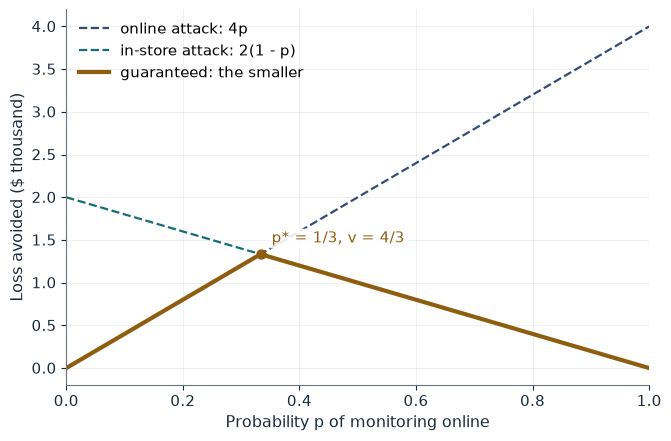

Retailer's p*              1/3 (0.333)
Fraudster's q*             1/3 (0.333)
Value v                    4/3 ($1,333)
Guaranteed with no mixing  0

Worked steps:
  1. 4p = 2(1 - p)
  2. p* = 2 / (4 + 2) = 1/3
  3. v = 4 x 1/3 = 4/3 = 1.333
  4. q* = 1/3

Equalizing 4p = 2(1 - p) gives (4 + 2)p = 2, so p* = 2 / 6 = 1/3 and v = 4 x 1/3 = 4/3, about $1,333 of avoided loss. The fraudster's q solves 4q = 2(1 - q), so q* = 1/3. Any pure choice guarantees 0.


In [2]:
show(minimax_picture(a=4, seen='no'))

Change one input, `a`, and hold the others at the book's values:

In [3]:
sweep(minimax_picture, 'a', [2, 4, 6], {'seen': 'no'}, ["Retailer's p*", 'Value v'])

a | Retailer's p* | Value v
2 | 1/2 (0.500) | 1 ($1,000)
4 | 1/3 (0.333) | 4/3 ($1,333)
6 | 1/4 (0.250) | 3/2 ($1,500)


Both sides mix with probability 1/3 and the value is 4/3, about \$1,333. If the fraudster sees the assignment, the guarantee falls to 0.

## 2. Nash equilibrium and existence

With the payoff at $(O,O)$ set to $-1$, a rival offering with probability $p$ gives

$$p(-1)+(1-p)6=6-7p, \qquad p(0)+(1-p)4=4-4p$$

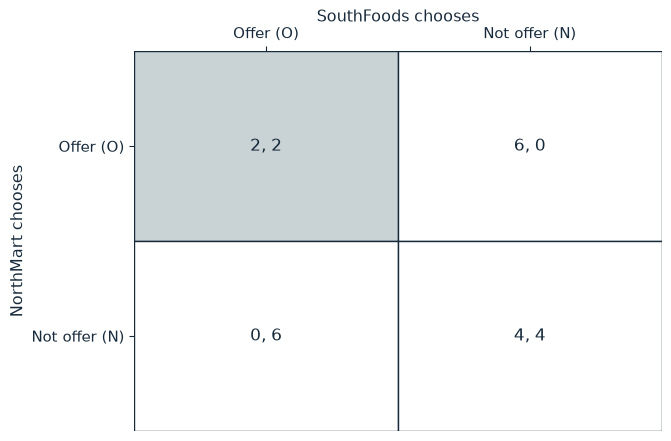

Pure equilibria        (O, O)
Offer dominant         yes
Mixed equilibrium      none
Payoff each at (N, N)  4

Worked steps:
  1. Best reply to O: Offer (2 vs 0)
  2. Best reply to N: Offer (6 vs 4)
  3. Pure equilibria: (O, O)

Against O, Offer pays 2 > 0; against N it pays 6 > 4. Offer is dominant, so (O, O) is the only equilibrium, with 2 each against 4 at (N, N): each chain gives up 4 - 2 = 2. There is no mixed equilibrium because Offer strictly dominates.


In [4]:
show(nash_picture(x=2))

Change one input, `x`, and hold the others at the book's values:

In [5]:
sweep(nash_picture, 'x', [2, 1, -1, -3], {}, ['Pure equilibria', 'Offer dominant', 'Mixed equilibrium'])

x | Pure equilibria | Offer dominant | Mixed equilibrium
2 | (O, O) | yes | none
1 | (O, O) | yes | none
-1 | (O, N) and (N, O) | no | p = 2/3, payoff 4/3 (1.33)
-3 | (O, N) and (N, O) | no | p = 2/5, payoff 12/5 (2.40)


With 2 each at (O, O), offering dominates and (O, O) is the unique equilibrium. At -1 there are two pure equilibria and a mixed one with p = 2/3 and payoff 4/3.

## 3. Common knowledge: adopting a standard by email

$$0.9(5)+0.1(-50)=-0.5, \qquad 0.9(5)+0.1(-10)=3.5>0$$

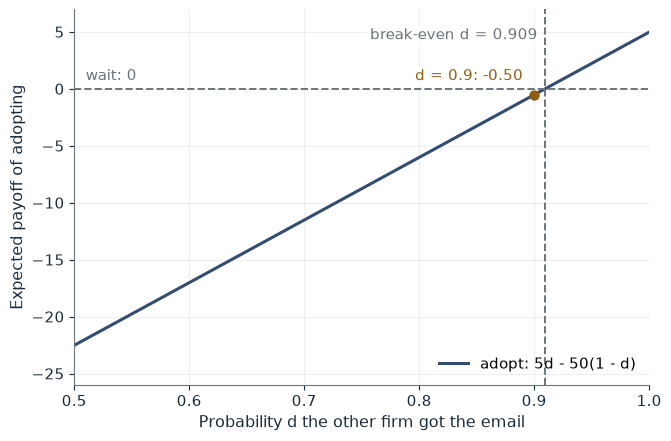

Expected payoff of adopting      -0.50
Break-even delivery probability  0.909
Decision                         wait

Worked steps:
  1. 0.9 x 5 = 4.50
  2. 0.10 x 50 = 5.00
  3. Expected = 4.50 - 5.00 = -0.50
  4. Break-even d = 50 / 55 = 0.909

Adopting pays 0.9 x 5 + 0.10 x (-50) = 4.50 - 5.00 = -0.50, against 0 for waiting, so Alpha should wait. Adoption needs d above 50 / (5 + 50) = 0.909.


In [6]:
show(ck_picture(d=0.9, loss=50))

Change one input, `d`, and hold the others at the book's values:

In [7]:
sweep(ck_picture, 'd', [0.8, 0.9, 0.99], {'loss': 50}, ['Expected payoff of adopting', 'Decision'])

d | Expected payoff of adopting | Decision
0.8 | -6.00 | wait
0.9 | -0.50 | wait
0.99 | 4.45 | adopt


With a \$50 solo loss Alpha waits unless delivery is above 50 / 55 = 0.909. With a \$10 loss it adopts.

## 4. Correlated equilibrium: the port's schedule

$$\frac{0.4}{0.4+0.2}=\frac{2}{3}, \qquad \frac{2}{3}(2)+\frac{1}{3}(4)=\frac{8}{3}, \qquad \frac{2}{3}(0)+\frac{1}{3}(6)=2$$

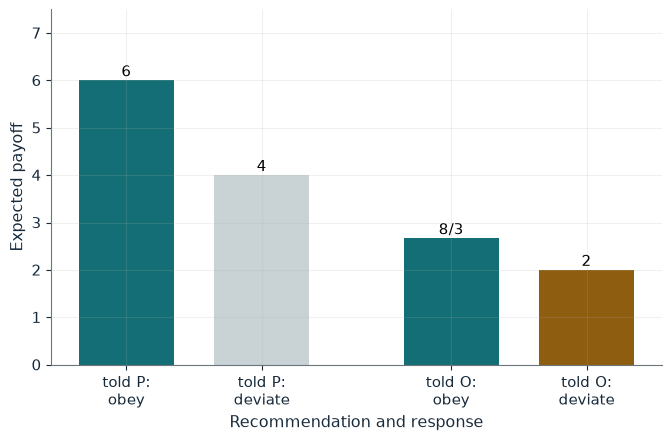

P(other told Peak | told Off-peak)  2/3 (0.667)
Obey after Off-peak                 8/3 (2.667)
Deviate after Off-peak              2 (2.000)
Schedule obeyed                     yes
Expected payoff each                4.00

Worked steps:
  1. pi = 0.4 / (0.4 + 0.2) = 2/3
  2. Obey = 2/3 x 2 + 1/3 x 4 = 8/3
  3. Deviate = 2/3 x 0 + 1/3 x 6 = 2
  4. Told Peak: obey 6 against deviate 4
  5. Obeyed: yes

After Off-peak the other was told Peak with probability 0.4 / (0.4 + 0.2) = 2/3. Obeying pays 2/3 x 2 + 1/3 x 4 = 8/3; switching to Peak pays 2/3 x 0 + 1/3 x 6 = 2. Obedience pays at least as much, and after a Peak recommendation 6 beats 4, so the schedule is obeyed. Expected payoff is 0.4 x 6 + 0.4 x 2 + 0.2 x 4 = 4.00.


In [8]:
show(correlated_picture(x=0.4, c=0))

Change one input, `x`, and hold the others at the book's values:

In [9]:
sweep(correlated_picture, 'x', [0.3, 0.4, 0.45], {'c': 0}, ['P(other told Peak | told Off-peak)', 'Obey after Off-peak', 'Deviate after Off-peak', 'Schedule obeyed'])

x | P(other told Peak | told Off-peak) | Obey after Off-peak | Deviate after Off-peak | Schedule obeyed
0.3 | 3/7 (0.429) | 22/7 (3.143) | 24/7 (3.429) | no
0.4 | 2/3 (0.667) | 8/3 (2.667) | 2 (2.000) | yes
0.45 | 9/11 (0.818) | 26/11 (2.364) | 12/11 (1.091) | yes


The book's schedule is obeyed and pays 4 each, against 3 under independent mixing. At x = 0.3 deviation after Off-peak pays more, and a collision payoff of 3 also breaks it.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

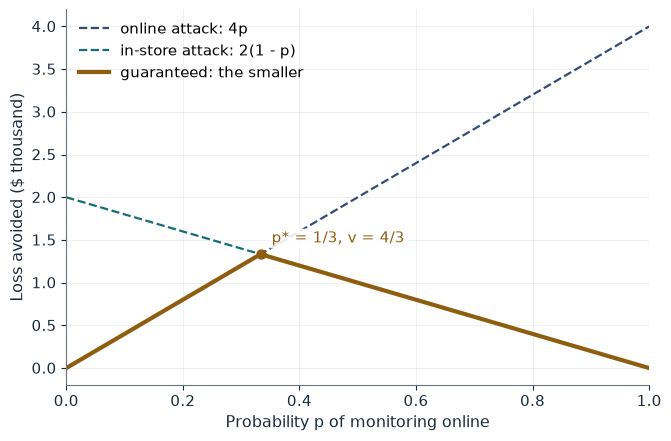

Retailer's p*              1/3 (0.333)
Fraudster's q*             1/3 (0.333)
Value v                    4/3 ($1,333)
Guaranteed with no mixing  0

Worked steps:
  1. 4p = 2(1 - p)
  2. p* = 2 / (4 + 2) = 1/3
  3. v = 4 x 1/3 = 4/3 = 1.333
  4. q* = 1/3

Equalizing 4p = 2(1 - p) gives (4 + 2)p = 2, so p* = 2 / 6 = 1/3 and v = 4 x 1/3 = 4/3, about $1,333 of avoided loss. The fraudster's q solves 4q = 2(1 - q), so q* = 1/3. Any pure choice guarantees 0.


In [10]:
show(minimax_picture(a=4, seen='no'))

## Practice

**1.** With the online catch worth 6, what are p* and v?

<details><summary>Answer</summary>

6p = 2(1 - p) gives p = 1/4; v = 1.5, or \$1,500.

</details>

**2.** At a payoff of -3 each when both offer, what are the mixed offer probability and payoff?

<details><summary>Answer</summary>

6 - 9p = 4 - 4p gives p = 2/5; payoff 4 - 4 x 0.4 = 2.4.

</details>

**3.** With delivery 0.8 and loss 10, should Alpha adopt?

<details><summary>Answer</summary>

0.8 x 5 - 0.2 x 10 = 2 > 0, so adopt.

</details>